<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 11 · Large-scale methods: KPM and continuum discretisation

* **KPM** expands $\rho(E)$, LDOS and the Kubo-Bastin conductivity in Chebyshev polynomials:
  this scales linearly with system size (millions of orbitals).
* **Continuum discretisation** turns a $\mathbf{k}\cdot\mathbf{p}$ Hamiltonian into a
  tight-binding model on a grid, which can then go through every tool in hopforge.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline
from hopforge import transport as tr
from hopforge import kpm

## 1. KPM density of states of a 200×200 graphene sheet (80,000 orbitals)

(80000, 80000) 320000 non-zeros


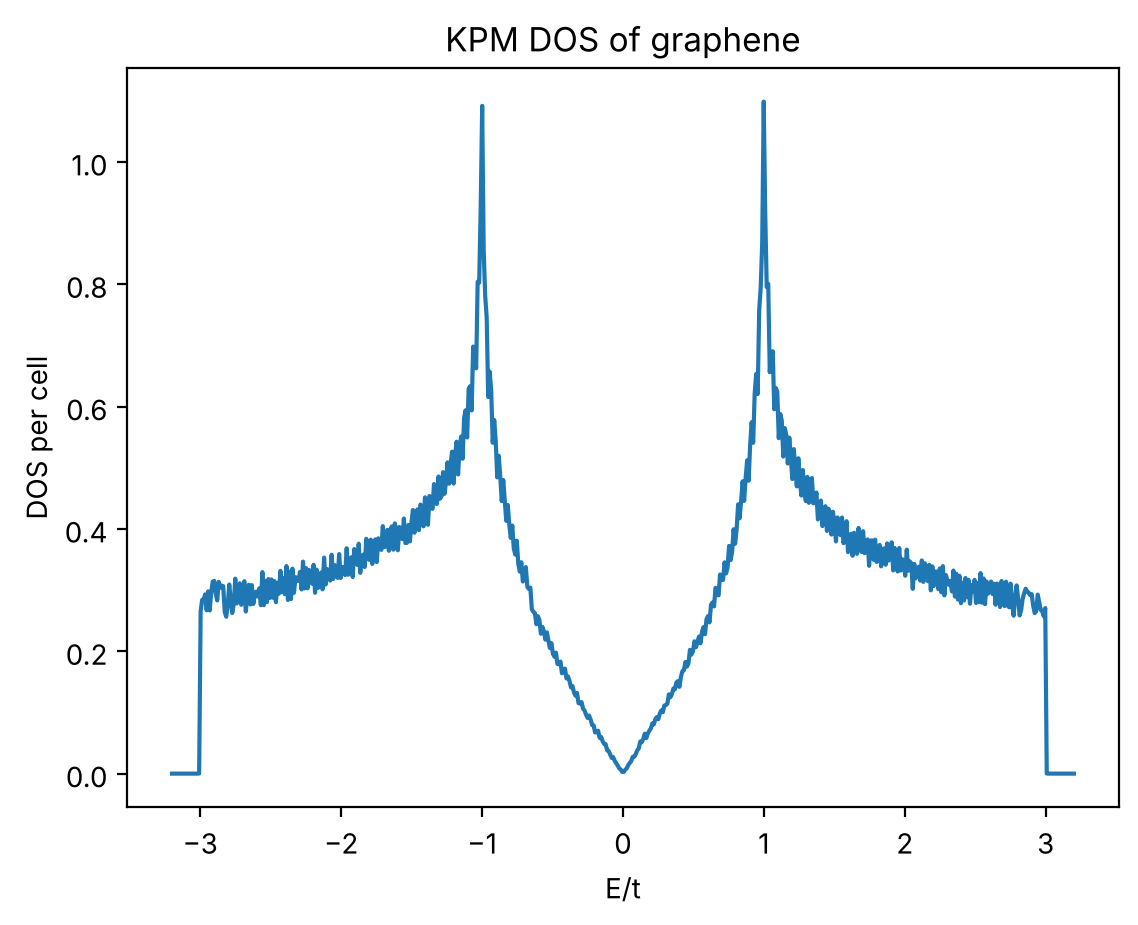

In [2]:
big = M.honeycomb().supercell([200, 200])
H = big.hamiltonian_sparse()
print(H.shape, H.nnz, "non-zeros")
E, rho = kpm.dos(H, np.linspace(-3.2, 3.2, 600), num_moments=1000, num_vectors=10)
plt.plot(E, rho / big.norb * 2); plt.xlabel("E/t"); plt.ylabel("DOS per cell"); plt.title("KPM DOS of graphene");

## 2. Disorder: the van Hove peaks broaden

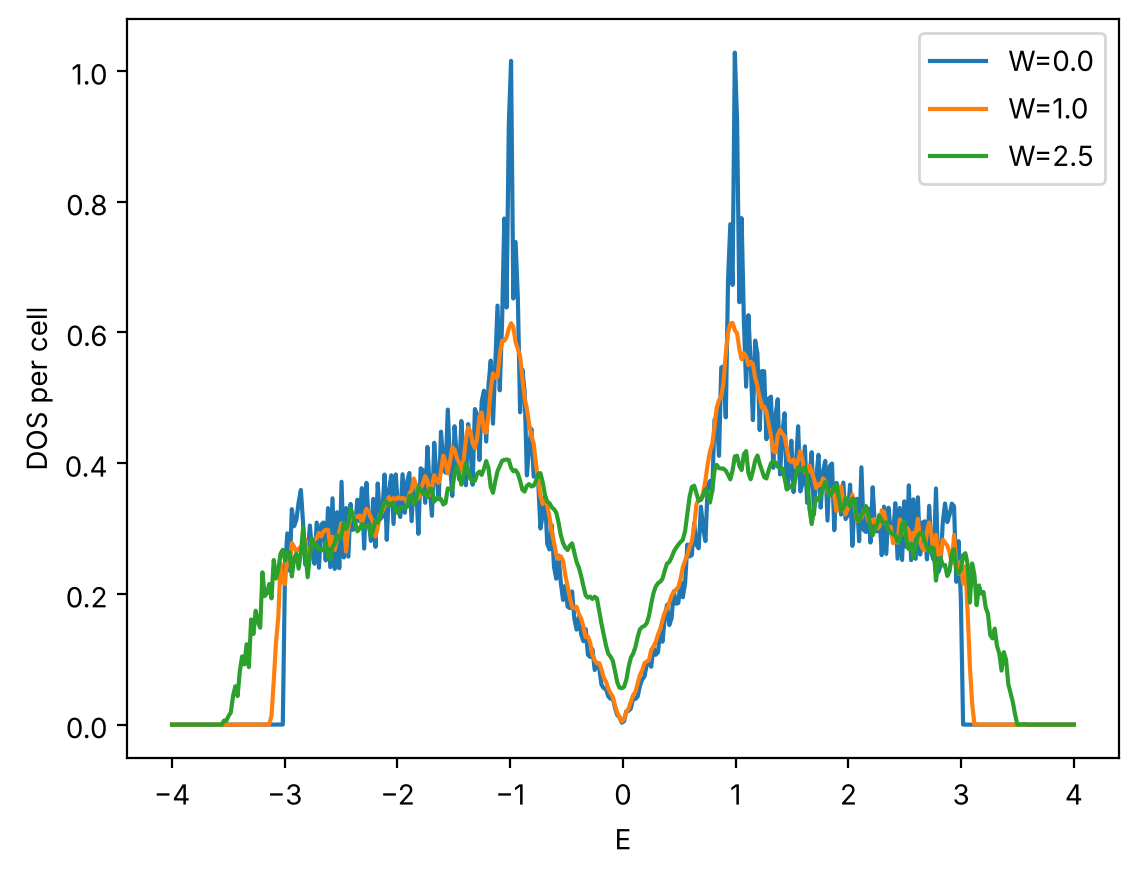

In [3]:
sc = M.honeycomb().supercell([100, 100])
for W in (0.0, 1.0, 2.5):
    m = hf.add_disorder(sc, W, seed=1)
    E, rho = kpm.dos(m.hamiltonian_sparse(), np.linspace(-4, 4, 400), num_moments=600, num_vectors=4)
    plt.plot(E, rho / sc.norb * 2, label=f"W={W}")
plt.legend(); plt.xlabel("E"); plt.ylabel("DOS per cell");

## 3. LDOS near a vacancy (exact KPM moments on chosen sites)

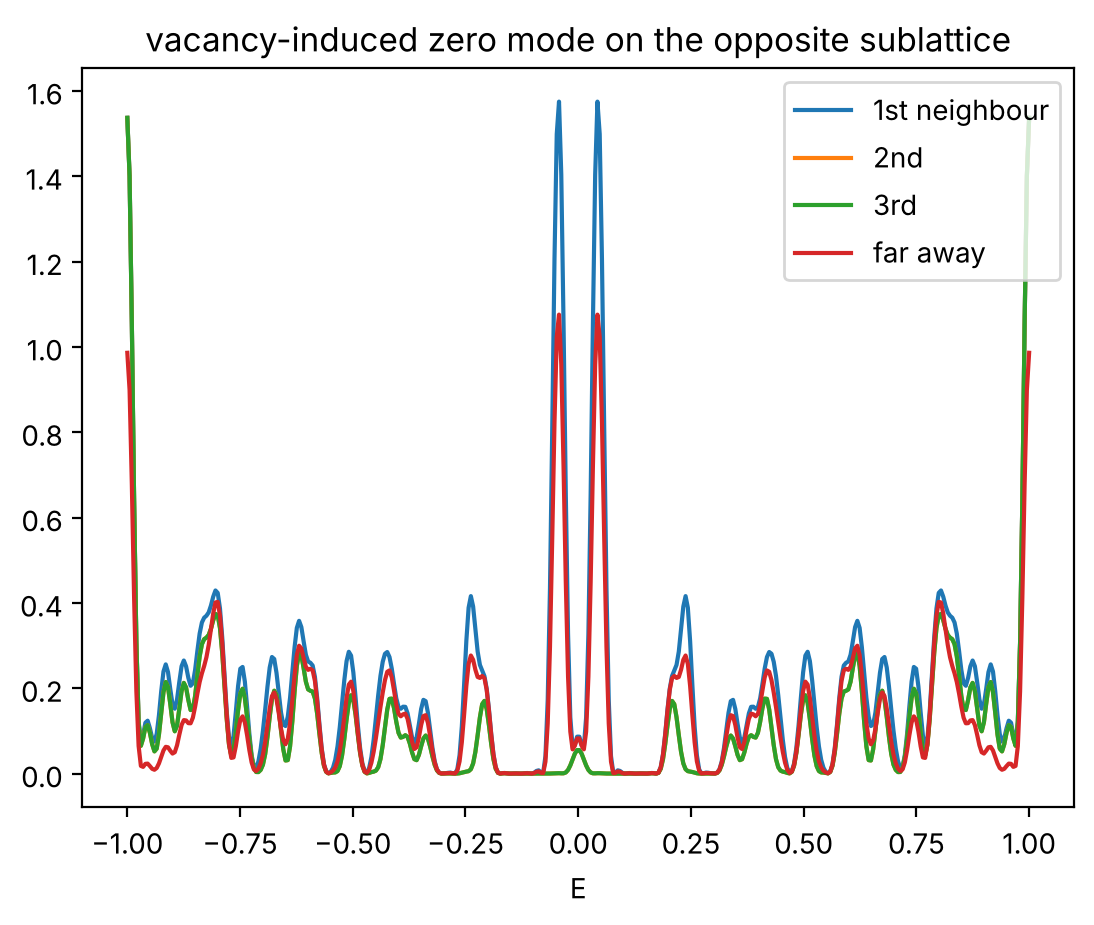

In [4]:
sc = M.honeycomb().supercell([30, 30]); vac = sc.remove_orbitals([0])
H = vac.hamiltonian_sparse(); E = np.linspace(-1, 1, 400)
P = vac.lat.positions; r0 = sc.lat.positions[0]
d = np.linalg.norm(P - r0, axis=1); near = np.argsort(d)[:3]; far = np.argsort(d)[-1]
L = kpm.ldos(H, list(near) + [far], E, num_moments=800)
for n, l in zip(["1st neighbour", "2nd", "3rd", "far away"], L): plt.plot(E, l, label=n)
plt.legend(); plt.xlabel("E"); plt.title("vacancy-induced zero mode on the opposite sublattice");

## 4. Kubo-Bastin Hall conductivity of a large disordered Chern insulator

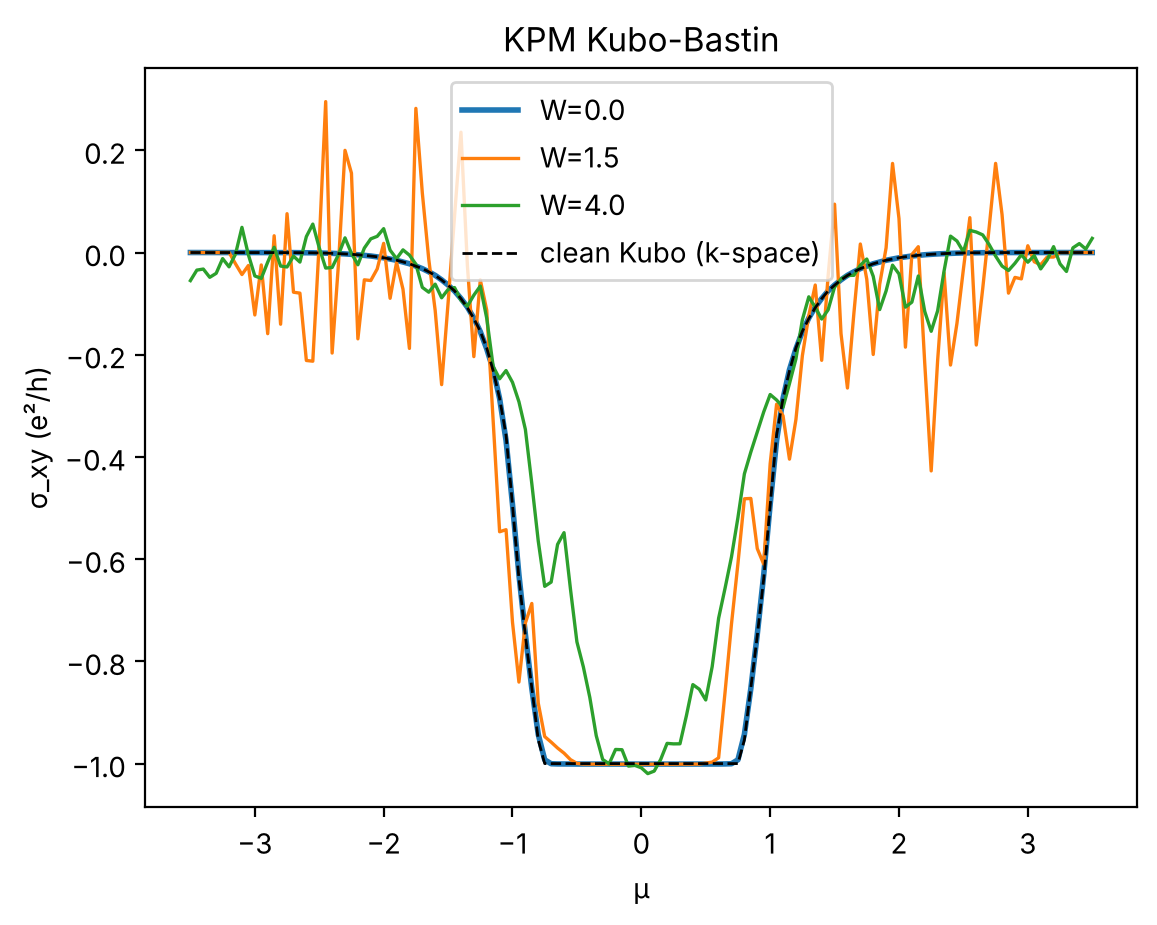

In [5]:
h = M.haldane(t2=0.15)
mus = np.linspace(-3.5, 3.5, 141)
for W in (0.0, 1.5, 4.0):
    m = hf.add_disorder(h.supercell([50, 50]), W, seed=2)
    sig = kpm.conductivity(m.hamiltonian_sparse(), m.velocity_sparse('x'), m.velocity_sparse('y'),
                           m.lat.cell_volume, mus, num_moments=256, num_vectors=16)
    plt.plot(mus, sig, lw=2 if W == 0 else 1.2, label=f"W={W}")
plt.plot(mus, hf.anomalous_hall(h, mus, 100, eta=0.02).sigma, "k--", lw=1, label="clean Kubo (k-space)")
plt.legend(); plt.xlabel("μ"); plt.ylabel("σ_xy (e²/h)"); plt.title("KPM Kubo-Bastin");

## 5. Continuum discretisation: from k·p to tight binding

Chern number of the discretised model: 1.0


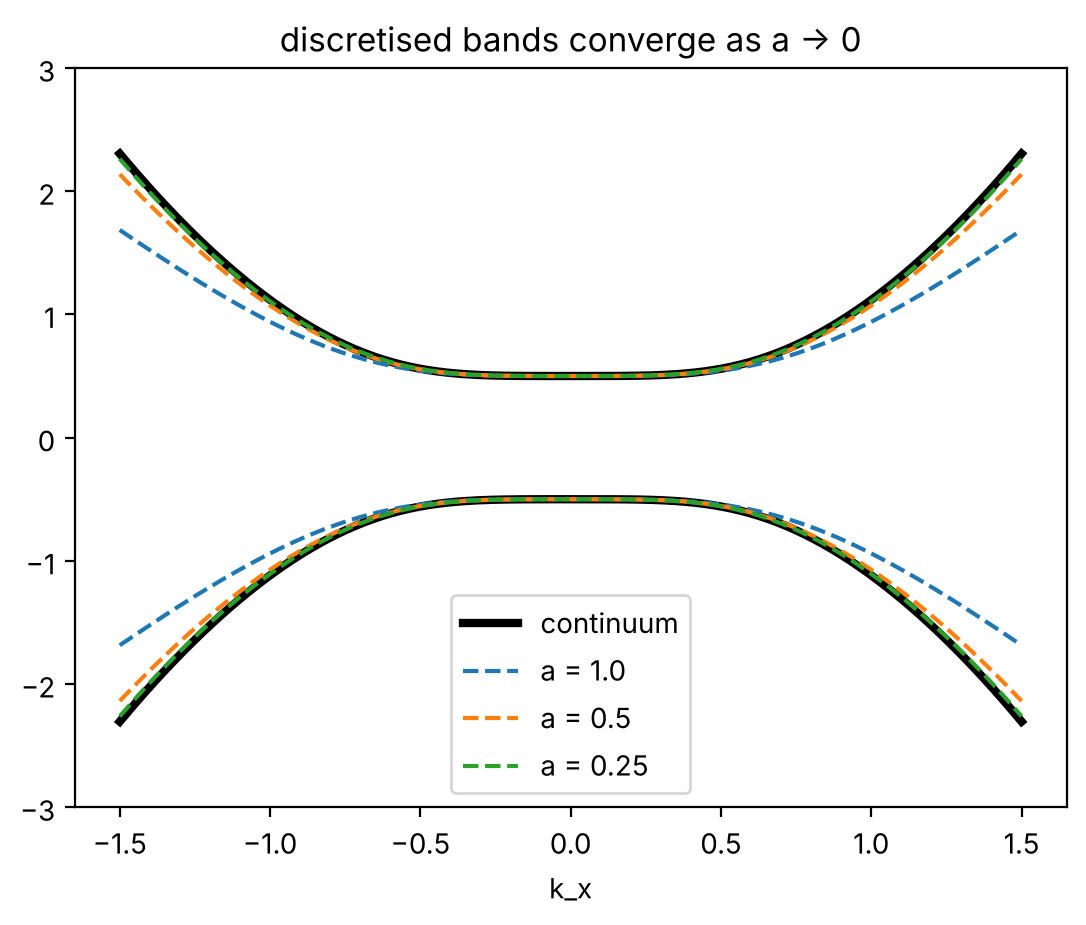

In [6]:
ex = "A*(k_x*sigma_x + k_y*sigma_y) + (M - B*(k_x**2 + k_y**2))*sigma_z"
p = dict(A=1.0, B=1.0, M=0.5)
f = hf.continuum.lambdify_continuum(ex, "xy", p)
k = np.linspace(-1.5, 1.5, 200)
Econt = np.array([np.linalg.eigvalsh(f(kk, 0)) for kk in k])
plt.plot(k, Econt[:, 0], "k", lw=3, label="continuum"); plt.plot(k, Econt[:, 1], "k", lw=3)
for n, a in enumerate((1.0, 0.5, 0.25)):
    m = hf.discretize(ex, "xy", a, p)
    Ed = m.energies(np.stack([k * a / (2*np.pi), 0*k], 1))
    plt.plot(k, Ed[:, 0], "--", color=f"C{n}", label=f"a = {a}"); plt.plot(k, Ed[:, 1], "--", color=f"C{n}")
plt.ylim(-3, 3); plt.legend(); plt.xlabel("k_x"); plt.title("discretised bands converge as a → 0")
print("Chern number of the discretised model:", hf.chern_number(hf.discretize(ex, "xy", 1.0, p), 1))

## 6. A Bi2Se3-type 3D TI straight from k·p, then a slab

Z2 indices: (1, 0, 0, 0)


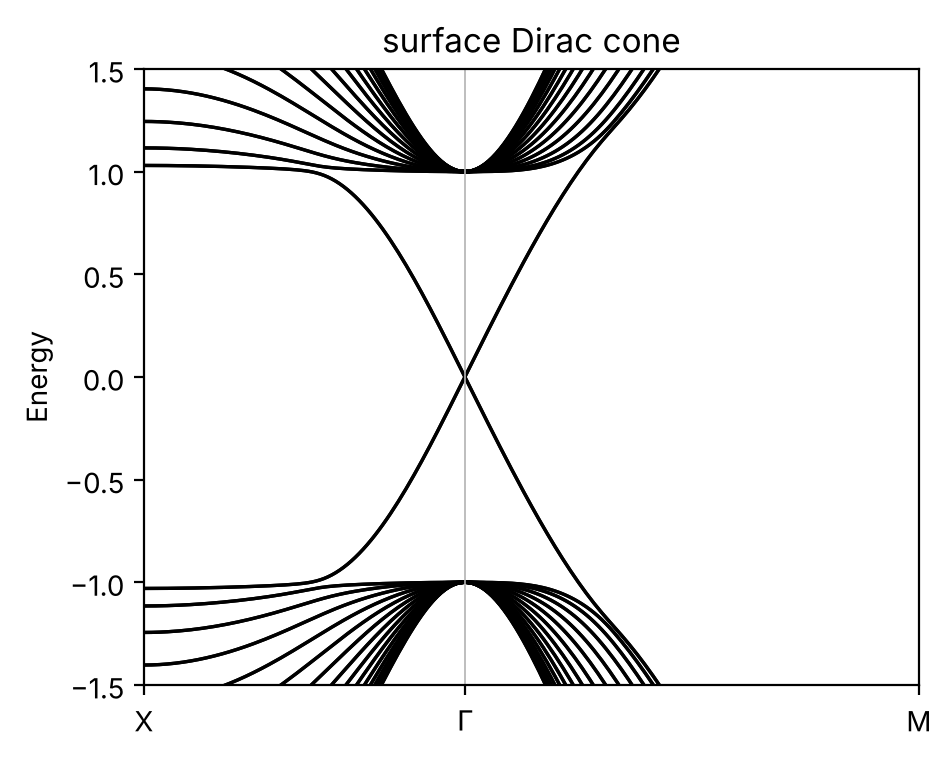

In [7]:
ti = "M0*tau_z - B*(k_x**2+k_y**2+k_z**2)*tau_z + A*(k_x*tau_x*sigma_x + k_y*tau_x*sigma_y + k_z*tau_x*sigma_z)"
mt = hf.discretize(ti, "xyz", 1.0, dict(M0=1.0, B=0.5, A=1.0))
print("Z2 indices:", hf.z2_3d(mt, 2, nk=24, nscan=25))
mt.slab(2, 16).plot_bands(["X", "G", "M"], ylim=(-1.5, 1.5), title="surface Dirac cone");

## 7. Continuum model + transport: a disordered BHZ quantum-well wire

In [8]:
bhz = ("C0 - D*(k_x**2+k_y**2) + A*(k_x*tau_x*sigma_z - k_y*tau_y)"
       " + (M0 - B*(k_x**2+k_y**2))*tau_z")
qw = hf.discretize(bhz, "xy", 1.0, dict(C0=0.0, D=0.0, A=0.6, B=1.0, M0=0.3))
for W in (0.0, 1.0):
    s = tr.System(qw, lambda r: 0 <= r[0] < 30 and 0 <= r[1] < 20, onsite=tr.anderson(W, seed=5) if W else None)
    s.attach_lead((-1, 0)); s.attach_lead((1, 0))
    print(f"W={W}: T(E=0.1) = {s.transmission(1, 0, 0.1):.4f}  (QSH: two helical channels)")

W=0.0: T(E=0.1) = 2.0000  (QSH: two helical channels)


W=1.0: T(E=0.1) = 1.9995  (QSH: two helical channels)


Note: exactly at the edge Dirac point (E = 0) a 20-site-wide ribbon has a tiny hybridisation gap between opposite edges, so probe slightly away from it or use wider systems.

## Exercises
1. Converge the KPM DOS of graphene near E = 0 versus the number of moments.
2. Find the disorder strength at which the Haldane Hall plateau is destroyed.
3. Discretise a Rashba 2DEG `k_x**2 + k_y**2 + alpha*(k_y*sigma_x - k_x*sigma_y)` and plot its spin texture.

---
## Quiz 11: KPM and continuum

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [9]:
quiz = hf.Quiz(11)
quiz.interactive()

In [10]:
quiz.show()

=== Quiz 11: Kernel polynomial method, large-scale Kubo-Bastin and continuum discretisation ===

Q1. The KPM expands spectral functions in
   (a) plane waves
   (b) Gaussians
   (c) Chebyshev polynomials of the rescaled Hamiltonian
   (d) Legendre series

Q2. Why must the spectrum be rescaled into (-1, 1)?
   (a) it does not have to be
   (b) Chebyshev polynomials are bounded and orthogonal only there
   (c) for Hermiticity
   (d) for units

Q3. The Jackson kernel
   (a) is a lead
   (b) adds disorder
   (c) computes C
   (d) damps Gibbs oscillations of the truncated series

Q4. The energy resolution of KPM with N moments scales as
   (a) log N
   (b) 1/N^2
   (c) N
   (d) 1/N

Q5. Stochastic trace evaluation uses
   (a) zero vectors
   (b) all basis vectors
   (c) eigenvectors
   (d) random-phase vectors with <r|A|r> averaged

Q6. If KPM resolves features finer than the level spacing of a finite supercell you see
   (a) nothing
   (b) the discrete levels (spiky DOS)
   (c) a smoother 

In [11]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0